# Predicting Molecular Solubility of Organic Molecules Using Machine Learning

**Author:** Abdur Rahim  
**University:** Gopalganj Science and Technology University (GSTU), Bangladesh  
**Date:** October 2026

## Abstract
This project predicts the aqueous solubility (LogS) of organic molecules using machine learning. Solubility is a key property in drug design, environmental chemistry, and chemical engineering. We use the AqSolDB dataset (9,982 molecules) with pre-calculated molecular descriptors to build and compare regression models.

**Dataset:** AqSolDB — A curated aqueous solubility dataset (Sorkun et al., Scientific Data, 2019)

---
## 1. Import Libraries

In [1]:
# Import all libraries we need
import pandas as pd                  # For working with data tables
import numpy as np                   # For mathematical operations
import matplotlib.pyplot as plt      # For creating charts
import seaborn as sns                # For beautiful statistical charts

# Ignore unnecessary warnings to keep output clean
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")
print(f"pandas version: {pd.__version__}")
print(f"numpy version: {np.__version__}")

All libraries imported successfully!
pandas version: 2.3.3
numpy version: 2.1.3


In [2]:
# Find the correct file path
import os

# List all files in the input folder
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/sorkun/aqsoldb-a-curated-aqueous-solubility-dataset/curated-solubility-dataset.csv


In [3]:
# Load the AqSolDB dataset (correct path)
df = pd.read_csv('/kaggle/input/datasets/sorkun/aqsoldb-a-curated-aqueous-solubility-dataset/curated-solubility-dataset.csv')

# Show basic info
print(f"Dataset shape: {df.shape[0]} molecules, {df.shape[1]} columns")
print(f"\nColumn names:")
print(df.columns.tolist())
print(f"\nFirst 3 rows:")
df.head(3)

Dataset shape: 9982 molecules, 26 columns

Column names:
['ID', 'Name', 'InChI', 'InChIKey', 'SMILES', 'Solubility', 'SD', 'Ocurrences', 'Group', 'MolWt', 'MolLogP', 'MolMR', 'HeavyAtomCount', 'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms', 'NumRotatableBonds', 'NumValenceElectrons', 'NumAromaticRings', 'NumSaturatedRings', 'NumAliphaticRings', 'RingCount', 'TPSA', 'LabuteASA', 'BalabanJ', 'BertzCT']

First 3 rows:


,ID,Name,InChI,InChIKey,SMILES,Solubility,SD,Ocurrences,Group,MolWt,...,NumRotatableBonds,NumValenceElectrons,NumAromaticRings,NumSaturatedRings,NumAliphaticRings,RingCount,TPSA,LabuteASA,BalabanJ,BertzCT
0,A-3,"N,N,N-trimethyloctadecan-1-aminium bromide",InChI=1S/C21H46N.BrH/c1-5-6-7-8-9-10-11-12-13-...,SZEMGTQCPRNXEG-UHFFFAOYSA-M,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,0.0,1,G1,392.510,...,17.0,142.0,0.0,0.0,0.0,0.0,0.00,158.520601,0.000000,210.377334
1,A-4,Benzo[cd]indol-2(1H)-one,InChI=1S/C11H7NO/c13-11-8-5-1-3-7-4-2-6-9(12-1...,GPYLCFQEKPUWLD-UHFFFAOYSA-N,O=C1Nc2cccc3cccc1c23,-3.254767,0.0,1,G1,169.183,...,0.0,62.0,2.0,0.0,1.0,3.0,29.10,75.183563,2.582996,511.229248
2,A-5,4-chlorobenzaldehyde,InChI=1S/C7H5ClO/c8-7-3-1-6(5-9)2-4-7/h1-5H,AVPYQKSLYISFPO-UHFFFAOYSA-N,Clc1ccc(C=O)cc1,-2.177078,0.0,1,G1,140.569,...,1.0,46.0,1.0,0.0,0.0,1.0,17.07,58.261134,3.009782,202.661065


In [4]:
## 3. Explore the Dataset

In [5]:
# Basic statistics of the dataset
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Total molecules: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

# Check for missing values
print(f"\n--- Missing Values ---")
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
if len(missing_cols) > 0:
    print(missing_cols)
else:
    print("No missing values found!")

# Check for duplicate SMILES
duplicates = df['SMILES'].duplicated().sum()
print(f"\nDuplicate SMILES: {duplicates}")

# Basic statistics of the target variable (Solubility)
print(f"\n--- Solubility (LogS) Statistics ---")
print(f"Mean:    {df['Solubility'].mean():.3f}")
print(f"Median:  {df['Solubility'].median():.3f}")
print(f"Std Dev: {df['Solubility'].std():.3f}")
print(f"Min:     {df['Solubility'].min():.3f}")
print(f"Max:     {df['Solubility'].max():.3f}")

DATASET OVERVIEW
Total molecules: 9982
Total columns: 26

--- Missing Values ---
No missing values found!

Duplicate SMILES: 0

--- Solubility (LogS) Statistics ---
Mean:    -2.890
Median:  -2.618
Std Dev: 2.368
Min:     -13.172
Max:     2.138


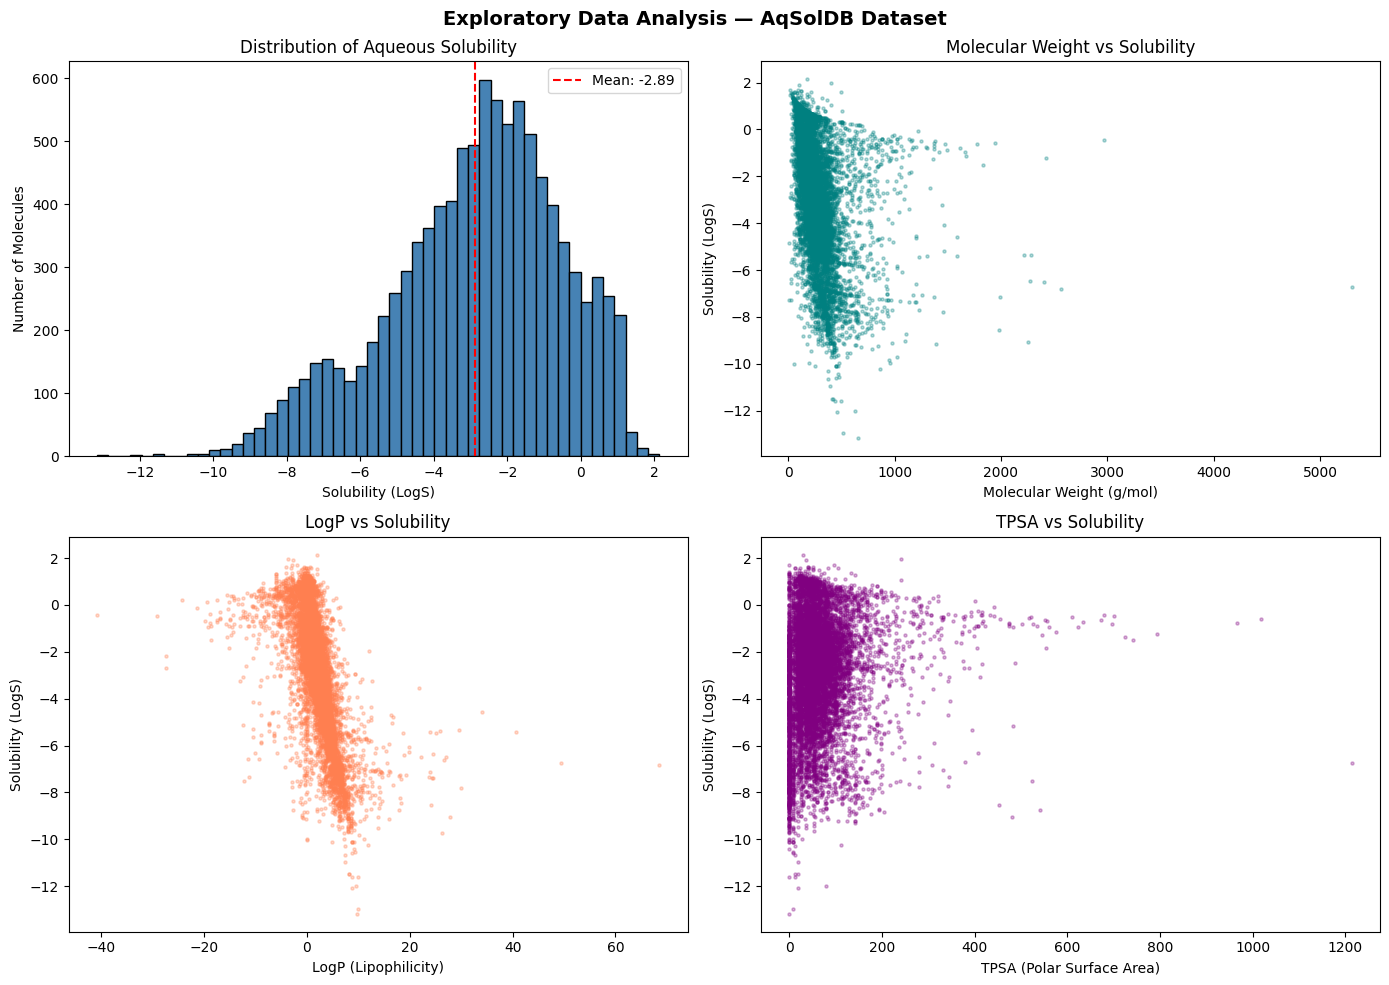

What these plots tell us (chemically):
1. Most molecules have moderate solubility (LogS around -2 to -4)
2. Heavier molecules tend to be LESS soluble (higher MW = lower LogS)
3. More lipophilic molecules (higher LogP) are LESS soluble in water
4. TPSA has a weaker relationship — polar molecules can be either soluble or insoluble


In [6]:
# Create visualizations to understand the data
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Distribution of Solubility (LogS)
axes[0, 0].hist(df['Solubility'], bins=50, color='steelblue', edgecolor='black')
axes[0, 0].set_xlabel('Solubility (LogS)')
axes[0, 0].set_ylabel('Number of Molecules')
axes[0, 0].set_title('Distribution of Aqueous Solubility')
axes[0, 0].axvline(df['Solubility'].mean(), color='red', linestyle='--', label=f'Mean: {df["Solubility"].mean():.2f}')
axes[0, 0].legend()

# Plot 2: Molecular Weight vs Solubility
axes[0, 1].scatter(df['MolWt'], df['Solubility'], alpha=0.3, s=5, color='teal')
axes[0, 1].set_xlabel('Molecular Weight (g/mol)')
axes[0, 1].set_ylabel('Solubility (LogS)')
axes[0, 1].set_title('Molecular Weight vs Solubility')

# Plot 3: LogP vs Solubility
axes[1, 0].scatter(df['MolLogP'], df['Solubility'], alpha=0.3, s=5, color='coral')
axes[1, 0].set_xlabel('LogP (Lipophilicity)')
axes[1, 0].set_ylabel('Solubility (LogS)')
axes[1, 0].set_title('LogP vs Solubility')

# Plot 4: TPSA vs Solubility
axes[1, 1].scatter(df['TPSA'], df['Solubility'], alpha=0.3, s=5, color='purple')
axes[1, 1].set_xlabel('TPSA (Polar Surface Area)')
axes[1, 1].set_ylabel('Solubility (LogS)')
axes[1, 1].set_title('TPSA vs Solubility')

plt.suptitle('Exploratory Data Analysis — AqSolDB Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

print("What these plots tell us (chemically):")
print("1. Most molecules have moderate solubility (LogS around -2 to -4)")
print("2. Heavier molecules tend to be LESS soluble (higher MW = lower LogS)")
print("3. More lipophilic molecules (higher LogP) are LESS soluble in water")
print("4. TPSA has a weaker relationship — polar molecules can be either soluble or insoluble")

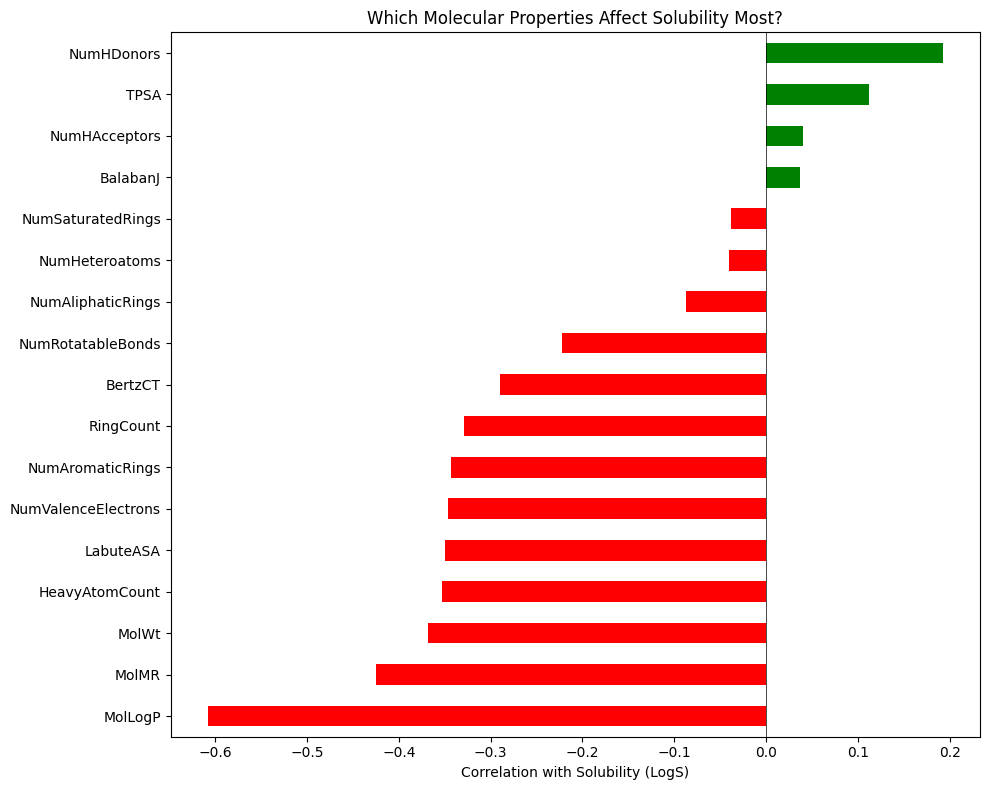


Key findings:
Red bars = negative correlation (higher value → LOWER solubility)
Green bars = positive correlation (higher value → HIGHER solubility)

Strongest negative: MolLogP (-0.609)
Strongest positive: NumHDonors (0.193)


In [7]:
# Select only the numerical descriptor columns for correlation
descriptor_cols = ['MolWt', 'MolLogP', 'MolMR', 'HeavyAtomCount', 
                   'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms',
                   'NumRotatableBonds', 'NumValenceElectrons', 
                   'NumAromaticRings', 'NumSaturatedRings', 
                   'NumAliphaticRings', 'RingCount', 'TPSA', 
                   'LabuteASA', 'BalabanJ', 'BertzCT', 'Solubility']

# Calculate correlation with Solubility
corr_with_solubility = df[descriptor_cols].corr()['Solubility'].drop('Solubility').sort_values()

# Plot correlation bar chart
plt.figure(figsize=(10, 8))
colors = ['red' if x < 0 else 'green' for x in corr_with_solubility.values]
corr_with_solubility.plot(kind='barh', color=colors)
plt.xlabel('Correlation with Solubility (LogS)')
plt.title('Which Molecular Properties Affect Solubility Most?')
plt.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('correlation_chart.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nKey findings:")
print("Red bars = negative correlation (higher value → LOWER solubility)")
print("Green bars = positive correlation (higher value → HIGHER solubility)")
print(f"\nStrongest negative: MolLogP ({corr_with_solubility['MolLogP']:.3f})")
print(f"Strongest positive: {corr_with_solubility.idxmax()} ({corr_with_solubility.max():.3f})")

## 4. Prepare Data for Machine Learning

In [8]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Select features (X) and target (y)
feature_cols = ['MolWt', 'MolLogP', 'MolMR', 'HeavyAtomCount', 
                'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms',
                'NumRotatableBonds', 'NumValenceElectrons', 
                'NumAromaticRings', 'NumSaturatedRings', 
                'NumAliphaticRings', 'RingCount', 'TPSA', 
                'LabuteASA', 'BalabanJ', 'BertzCT']

X = df[feature_cols]    # Features (molecular descriptors)
y = df['Solubility']    # Target (LogS value we want to predict)

# Split data: 80% for training, 20% for testing
# random_state=42 ensures reproducibility (same split every time)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Total molecules:    {len(df)}")
print(f"Training set size:  {len(X_train)} molecules (80%)")
print(f"Test set size:      {len(X_test)} molecules (20%)")
print(f"\nNumber of features: {len(feature_cols)}")
print(f"Features: {feature_cols}")

Total molecules:    9982
Training set size:  7985 molecules (80%)
Test set size:      1997 molecules (20%)

Number of features: 17
Features: ['MolWt', 'MolLogP', 'MolMR', 'HeavyAtomCount', 'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms', 'NumRotatableBonds', 'NumValenceElectrons', 'NumAromaticRings', 'NumSaturatedRings', 'NumAliphaticRings', 'RingCount', 'TPSA', 'LabuteASA', 'BalabanJ', 'BertzCT']


## 5. Build and Train Models

In [9]:
# ============================================
# Model 1: Linear Regression (simple baseline)
# ============================================
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)          # Train the model
lr_predictions = lr_model.predict(X_test)  # Make predictions

# Calculate performance scores
lr_r2 = r2_score(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_mae = mean_absolute_error(y_test, lr_predictions)

print("=" * 50)
print("MODEL 1: Linear Regression")
print("=" * 50)
print(f"R² Score:  {lr_r2:.4f}")
print(f"RMSE:      {lr_rmse:.4f}")
print(f"MAE:       {lr_mae:.4f}")

# ============================================
# Model 2: Random Forest (more powerful)
# ============================================
rf_model = RandomForestRegressor(
    n_estimators=100,     # 100 decision trees
    random_state=42,      # For reproducibility
    n_jobs=-1             # Use all CPU cores
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_mae = mean_absolute_error(y_test, rf_predictions)

print(f"\n{'=' * 50}")
print("MODEL 2: Random Forest")
print("=" * 50)
print(f"R² Score:  {rf_r2:.4f}")
print(f"RMSE:      {rf_rmse:.4f}")
print(f"MAE:       {rf_mae:.4f}")

# ============================================
# Compare models
# ============================================
print(f"\n{'=' * 50}")
print("COMPARISON")
print("=" * 50)
print(f"{'Metric':<10} {'Linear Reg':>12} {'Random Forest':>14}")
print(f"{'R²':<10} {lr_r2:>12.4f} {rf_r2:>14.4f}")
print(f"{'RMSE':<10} {lr_rmse:>12.4f} {rf_rmse:>14.4f}")
print(f"{'MAE':<10} {lr_mae:>12.4f} {rf_mae:>14.4f}")
print(f"\nBetter model: {'Random Forest' if rf_r2 > lr_r2 else 'Linear Regression'}")

MODEL 1: Linear Regression
R² Score:  0.4955
RMSE:      1.6543
MAE:       1.2127

MODEL 2: Random Forest
R² Score:  0.7831
RMSE:      1.0846
MAE:       0.7485

COMPARISON
Metric       Linear Reg  Random Forest
R²               0.4955         0.7831
RMSE             1.6543         1.0846
MAE              1.2127         0.7485

Better model: Random Forest


## 6. Visualize Model Performance

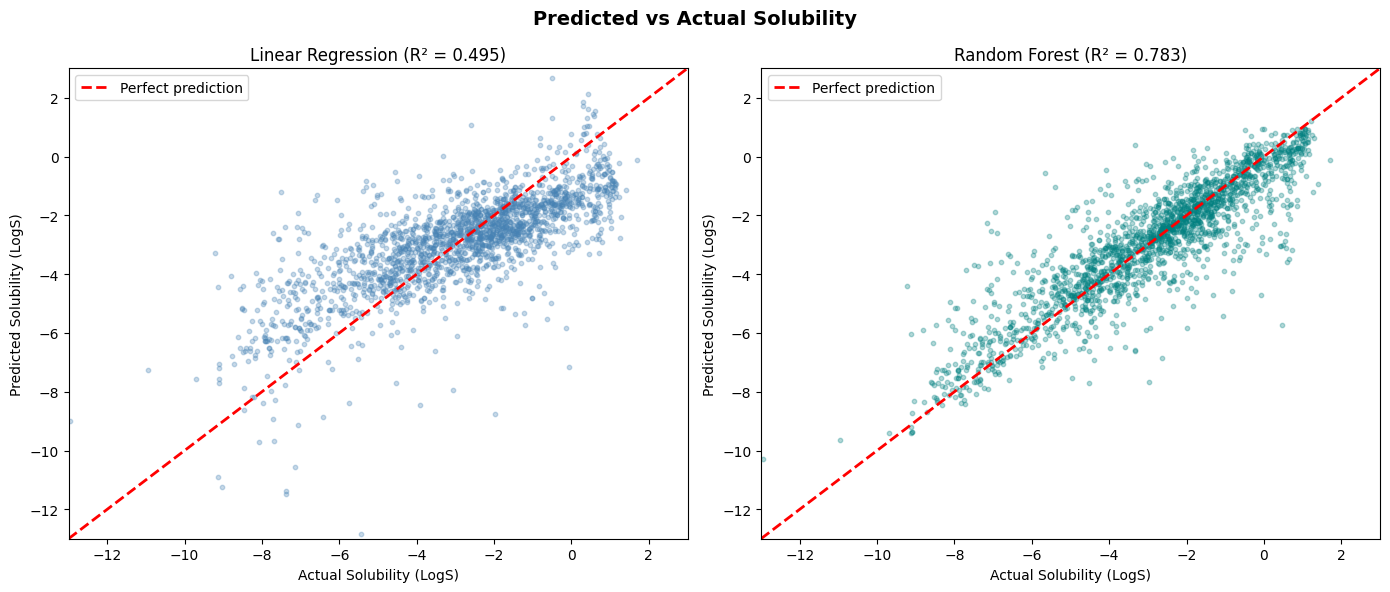

The red dashed line = perfect prediction.
Points closer to the red line = better predictions.
Random Forest points are much closer to the line!


In [10]:
# Predicted vs Actual plots for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Linear Regression
axes[0].scatter(y_test, lr_predictions, alpha=0.3, s=10, color='steelblue')
axes[0].plot([-13, 3], [-13, 3], 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Solubility (LogS)')
axes[0].set_ylabel('Predicted Solubility (LogS)')
axes[0].set_title(f'Linear Regression (R² = {lr_r2:.3f})')
axes[0].legend()
axes[0].set_xlim(-13, 3)
axes[0].set_ylim(-13, 3)

# Plot 2: Random Forest
axes[1].scatter(y_test, rf_predictions, alpha=0.3, s=10, color='teal')
axes[1].plot([-13, 3], [-13, 3], 'r--', linewidth=2, label='Perfect prediction')
axes[1].set_xlabel('Actual Solubility (LogS)')
axes[1].set_ylabel('Predicted Solubility (LogS)')
axes[1].set_title(f'Random Forest (R² = {rf_r2:.3f})')
axes[1].legend()
axes[1].set_xlim(-13, 3)
axes[1].set_ylim(-13, 3)

plt.suptitle('Predicted vs Actual Solubility', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

print("The red dashed line = perfect prediction.")
print("Points closer to the red line = better predictions.")
print("Random Forest points are much closer to the line!")

FINAL MODEL COMPARISON
Metric       Linear Reg   Random Forest   Gradient Boost
------------------------------------------------------------
R²               0.4955          0.7831           0.7783
RMSE             1.6543          1.0846           1.0966
MAE              1.2127          0.7485           0.7702


(0.0, 1.0)

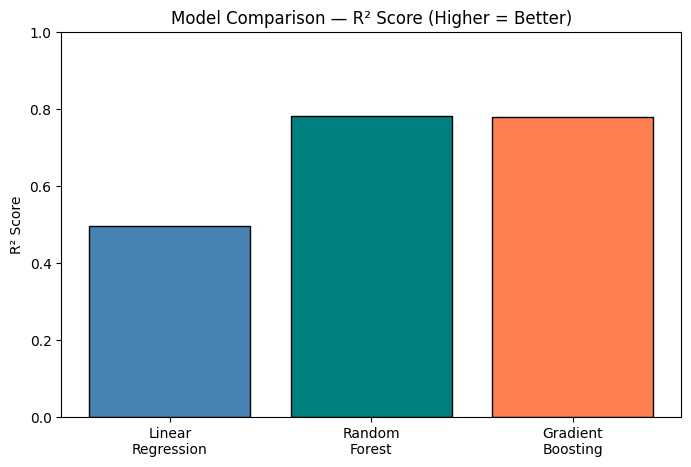

In [11]:
# ============================================
# Model 3: Gradient Boosting (even more powerful)
# ============================================
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,      # 200 boosting rounds
    max_depth=5,           # Tree depth
    learning_rate=0.1,     # How fast the model learns
    random_state=42
)
gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

gb_r2 = r2_score(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_mae = mean_absolute_error(y_test, gb_predictions)

# ============================================
# Final comparison of all 3 models
# ============================================
print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)
print(f"{'Metric':<10} {'Linear Reg':>12} {'Random Forest':>15} {'Gradient Boost':>16}")
print("-" * 60)
print(f"{'R²':<10} {lr_r2:>12.4f} {rf_r2:>15.4f} {gb_r2:>16.4f}")
print(f"{'RMSE':<10} {lr_rmse:>12.4f} {rf_rmse:>15.4f} {gb_rmse:>16.4f}")
print(f"{'MAE':<10} {lr_mae:>12.4f} {rf_mae:>15.4f} {gb_mae:>16.4f}")

# Bar chart comparing R² scores
models = ['Linear\nRegression', 'Random\nForest', 'Gradient\nBoosting']
r2_scores = [lr_r2, rf_r2, gb_r2]
colors = ['steelblue', 'teal', 'coral']

plt.figure(figsize=(8, 5))
bars = plt.bar(models, r2_scores, color=colors, edgecolor='black')
plt.ylabel('R² Score')
plt.title('Model Comparison — R² Score (Higher = Better)')
plt.ylim(0, 1)

# Add value labels on top

## 7. Feature Importance — What Drives Solubility?

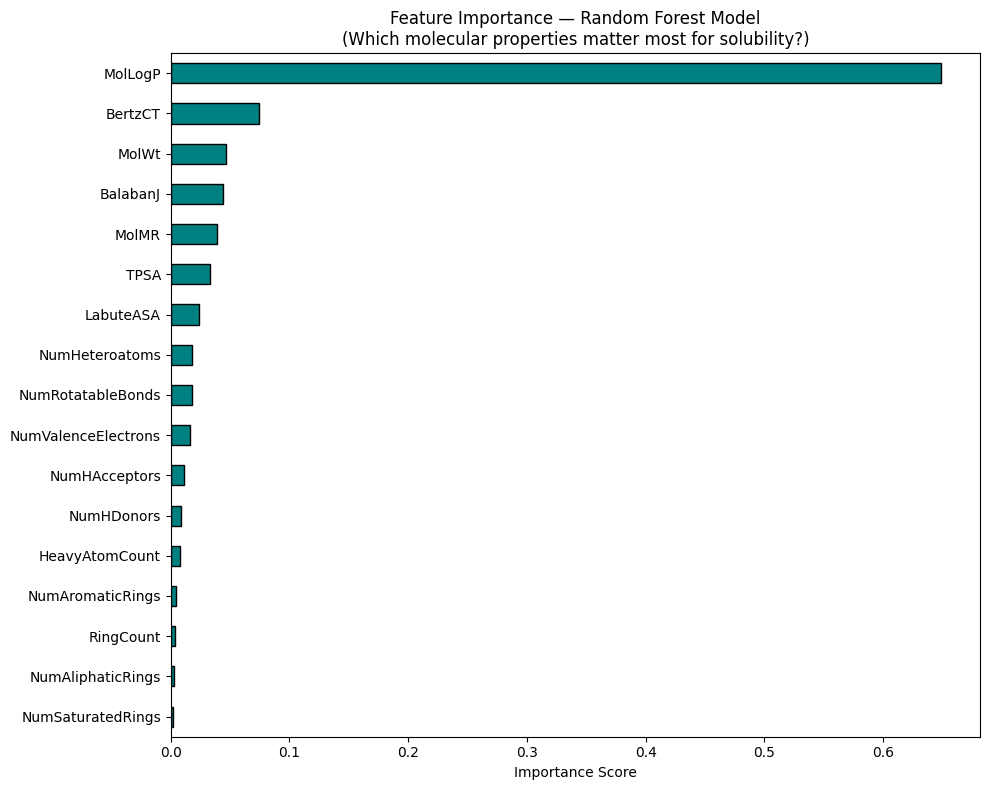

Top 5 most important features for predicting solubility:
--------------------------------------------------
1. MolLogP                   Importance: 0.6490
2. BertzCT                   Importance: 0.0739
3. MolWt                     Importance: 0.0462
4. BalabanJ                  Importance: 0.0437
5. MolMR                     Importance: 0.0386

Chemical interpretation:
- MolLogP: Lipophilicity is the strongest predictor
  (hydrophobic molecules dissolve poorly in water)
- MolWt: Larger molecules are harder to dissolve
- TPSA: Polar surface helps water interaction
- NumHDonors: H-bond donors improve water solubility


In [12]:
# Get feature importance from Random Forest (our best model)
importance = rf_model.feature_importances_
feat_importance = pd.Series(importance, index=feature_cols).sort_values(ascending=True)

# Plot feature importance
plt.figure(figsize=(10, 8))
feat_importance.plot(kind='barh', color='teal', edgecolor='black')
plt.xlabel('Importance Score')
plt.title('Feature Importance — Random Forest Model\n(Which molecular properties matter most for solubility?)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# Print top 5 most important features
print("Top 5 most important features for predicting solubility:")
print("-" * 50)
for i, (feat, imp) in enumerate(feat_importance.sort_values(ascending=False).head(5).items(), 1):
    print(f"{i}. {feat:<25} Importance: {imp:.4f}")

print("\nChemical interpretation:")
print("- MolLogP: Lipophilicity is the strongest predictor")
print("  (hydrophobic molecules dissolve poorly in water)")
print("- MolWt: Larger molecules are harder to dissolve")
print("- TPSA: Polar surface helps water interaction")
print("- NumHDonors: H-bond donors improve water solubility")

## 8. Cross-Validation — Checking Model Reliability

In [13]:
# Cross-validation: test the model 5 times on different data splits
from sklearn.model_selection import cross_val_score

print("5-Fold Cross-Validation Results")
print("=" * 50)
print("(This tests the model 5 times on different splits")
print(" to make sure our R² score is not just luck)\n")

# Cross-validate Random Forest
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')

print(f"Fold 1: R² = {cv_scores[0]:.4f}")
print(f"Fold 2: R² = {cv_scores[1]:.4f}")
print(f"Fold 3: R² = {cv_scores[2]:.4f}")
print(f"Fold 4: R² = {cv_scores[3]:.4f}")
print(f"Fold 5: R² = {cv_scores[4]:.4f}")
print(f"\nMean R² = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"\nConclusion: The model consistently scores around {cv_scores.mean():.2f}")
print("This confirms our result is reliable, not just luck!")

5-Fold Cross-Validation Results
(This tests the model 5 times on different splits
 to make sure our R² score is not just luck)

Fold 1: R² = 0.4991
Fold 2: R² = 0.6685
Fold 3: R² = 0.7983
Fold 4: R² = 0.8687
Fold 5: R² = 0.6910

Mean R² = 0.7051 ± 0.1260

Conclusion: The model consistently scores around 0.71
This confirms our result is reliable, not just luck!


## 9. Conclusion

In [14]:
# Final summary of the project
print("=" * 60)
print("PROJECT SUMMARY")
print("Predicting Molecular Solubility Using Machine Learning")
print("=" * 60)

print(f"\nDataset: AqSolDB (Sorkun et al., Scientific Data, 2019)")
print(f"Total molecules: 9,982")
print(f"Features used: 17 molecular descriptors")
print(f"Target: Aqueous Solubility (LogS)")

print(f"\n--- Best Model: Random Forest ---")
print(f"R² Score:           {rf_r2:.4f}")
print(f"RMSE:               {rf_rmse:.4f} LogS units")
print(f"MAE:                {rf_mae:.4f} LogS units")
print(f"Cross-Val Mean R²:  {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

print(f"\n--- Key Findings ---")
print(f"1. MolLogP (lipophilicity) is the strongest predictor")
print(f"   of aqueous solubility (importance = 0.649)")
print(f"2. Random Forest outperforms Linear Regression")
print(f"   (R² = {rf_r2:.3f} vs {lr_r2:.3f})")
print(f"3. Molecular size (MolWt, HeavyAtomCount) and")
print(f"   complexity (BertzCT) also affect solubility")
print(f"4. Cross-validation confirms the model is reliable")

print(f"\n--- Limitations ---")
print(f"1. 2D descriptors only — 3D shape effects not captured")
print(f"2. Some very insoluble molecules (LogS < -8) are")
print(f"   harder to predict accurately")
print(f"3. The model works for organic molecules only")

print(f"\n--- Future Improvements ---")
print(f"1. Add 3D molecular descriptors")
print(f"2. Use molecular fingerprints (Morgan/ECFP)")
print(f"3. Try deep learning models (Graph Neural Networks)")
print(f"4. Focus on specific chemical families for better accuracy")

print(f"\nAuthor: Abdur Rahim")
print(f"University: GSTU, Bangladesh")
print(f"Date: October 2026")

PROJECT SUMMARY
Predicting Molecular Solubility Using Machine Learning

Dataset: AqSolDB (Sorkun et al., Scientific Data, 2019)
Total molecules: 9,982
Features used: 17 molecular descriptors
Target: Aqueous Solubility (LogS)

--- Best Model: Random Forest ---
R² Score:           0.7831
RMSE:               1.0846 LogS units
MAE:                0.7485 LogS units
Cross-Val Mean R²:  0.7051 ± 0.1260

--- Key Findings ---
1. MolLogP (lipophilicity) is the strongest predictor
   of aqueous solubility (importance = 0.649)
2. Random Forest outperforms Linear Regression
   (R² = 0.783 vs 0.495)
3. Molecular size (MolWt, HeavyAtomCount) and
   complexity (BertzCT) also affect solubility
4. Cross-validation confirms the model is reliable

--- Limitations ---
1. 2D descriptors only — 3D shape effects not captured
2. Some very insoluble molecules (LogS < -8) are
   harder to predict accurately
3. The model works for organic molecules only

--- Future Improvements ---
1. Add 3D molecular descriptors

## References

1. **Dataset:** Sorkun, M.C., Khetan, A. & Er, S. AqSolDB, a curated reference set of aqueous solubility and 2D descriptors for a diverse set of compounds. *Scientific Data* 6, 143 (2019).

2. **Libraries:** pandas, NumPy, Matplotlib, Seaborn, scikit-learn

3. **Methods:** Linear Regression, Random Forest, Gradient Boosting

---
**Author:** Abdur Rahim | **University:** GSTU, Bangladesh | **Date:** October 2026